# Modelo de referencia para reconocimiento de actividad humana
## Proyecto Integrador — Avance 3 — Equipo 1

| Integrante | Matrícula |
|---|---|
| Isaura Yutsil Flores Escamilla | A01796552 |
| Paola Alejandra León Guarneros | A01796230 |
| Dylan Ulises Quiroz Hernández | A01796578 |

**Objetivo:** evaluar la viabilidad de reconocer siete actividades de manejo manual de cargas a partir de sEMG en sujetos no observados. Este entregable contiene código pendiente de ejecución: los resultados del Avance 2 son antecedentes, no resultados nuevos.

| Criterio de semana 3 | Evidencia prevista |
|---|---|
| Algoritmo | Regresión logística balanceada, contrastada con dos controles triviales |
| Características importantes | Filtro de correlación e información mutua; coeficientes e importancia por permutación con gráficos |
| Sub/sobreajuste | Métricas de entrenamiento y validación cruzada por sujeto; comparación con validación y prueba final |
| Métrica | F1 macro principal; exactitud balanceada, exactitud global y reporte por clase como complementos |
| Desempeño | Umbrales explícitos, comparación con controles e histórico, decisión calculada al ejecutar |


## 1. Continuidad con los avances y adaptación de la plantilla

El Avance 1 identificó desbalance, diferencias entre sujetos, tres ensayos con señal anómala y dos con etiquetas inconsistentes. El Avance 2 excluyó esos cinco archivos, conservó los intervalos no anotados como desconocidos y exportó 202 características por ventana, calculadas sobre ocho canales `Norm_RMS` en %MVC.

Se conservan **12 Hz**, **4 segundos de contexto**, salto supervisado de **0.5 segundos** y la **etiqueta del instante final**. Esta última decisión del Avance 2 permite ventanas con transiciones y reemplaza la recomendación inicial de exigir pureza de clase. Las clases son `N`, `LF`, `K`, `PT`, `LT`, `W` y `PF`.

La estructura sigue `06_CPC_fs_configurable.ipynb`: configuración → lectura de exportaciones → modelos → entrenamiento/evaluación → diagnósticos → comparación → prueba cerrada. El código base del baseline procede de su **sección 9**, que utiliza características manuales, escalamiento y regresión logística balanceada. Se añade la variante con selección del Avance 2 para mantener un puente con su histórico. CPC–xLSTM es el modelo complejo que deberá superar esta referencia; no es necesario repetir su barrido para establecer el baseline solicitado.

La partición permanece fija: entrenamiento **1–10**, validación **11–12**, prueba **13–14**. Sujeto, tarea, lado, carga, condición, archivo, tiempo y diagnósticos derivados de etiquetas no son predictores.

**Alcance:** clasificación de actividades; la estimación de carga y la fusión con MVNX quedan fuera de esta etapa. La evaluación es offline: el antialias de fase cero del Avance 2 utiliza muestras futuras, por lo que estos resultados no demostrarán causalidad de extremo a extremo ni desempeño en tiempo real.


## 2. Configuración, métrica y desempeño mínimo

Se elige **F1 macro** porque da el mismo peso a cada actividad; la exactitud global puede ocultar errores en clases minoritarias ante el predominio de `N` (~43 % en el EDA). La exactitud balanceada resume el recall por clase. Se mostrarán también precisión, recall y F1 individuales y matrices de confusión.

El histórico guardado en el Avance 2, a 12 Hz y usando sólo señal, es **F1 macro CV = 0.3608 ± 0.0426**, **F1 macro de validación = 0.4153** y **exactitud balanceada de validación = 0.4698**. La desviación corresponde a folds, no a un intervalo de confianza. La reproducción exacta puede variar con versiones del entorno.

Se propone, antes del ajuste, un mínimo exploratorio de **F1 macro ≥ 0.40**, **exactitud balanceada ≥ 0.45** y **ganancia de F1 macro ≥ 0.10** frente al mejor control trivial del mismo conjunto. El 0.40 conserva aproximadamente el nivel histórico; 0.45 queda próximo al 0.4698 observado y por encima del azar balanceado de 1/7. Estos umbrales son propuestas técnicas para viabilidad, pendientes de validación con costos de error del negocio; no son criterios de despliegue. El F1 macro del azar depende de las distribuciones: no debe suponerse que vale 1/7.

La frecuencia es configurable, como en la plantilla. Las cifras históricas anteriores sólo se compararán directamente cuando `TARGET_FS == 12`. `TEST_OPEN = False` permite desarrollar y revisar sin abrir la prueba.


In [3]:
# Importaciones y parámetros; esta celda no instala dependencias ni ejecuta otros notebooks.
import hashlib
import json
from functools import partial
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from IPython.display import display
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.feature_selection import SelectPercentile, VarianceThreshold, mutual_info_classif
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay, accuracy_score, balanced_accuracy_score,
    classification_report, f1_score, make_scorer,
)
from sklearn.model_selection import GroupKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import RobustScaler, StandardScaler

SEED, TARGET_FS, N_SPLITS = 42, 12, 5
TEST_OPEN = False  # Cambiar sólo tras congelar el protocolo de desarrollo.
N_JOBS, PERM_REPEATS = 1, 5  # Secuencial limita memoria; permutar 202 variables tiene costo.
MIN_F1, MIN_BAL_ACC, MIN_GAIN, GAP_ALERT = 0.40, 0.45, 0.10, 0.10
EXPECTED_LABELS = ['N', 'LF', 'K', 'PT', 'LT', 'W', 'PF']
EXPECTED_SUBJECTS = {'train': set(range(1, 11)), 'validation': {11, 12}, 'test': {13, 14}}
REPO_DIR = next((p for p in [Path.cwd(), *Path.cwd().parents]
                 if (p / 'pyproject.toml').exists()), None)
if REPO_DIR is None:
    raise FileNotFoundError('Abrir el notebook desde el repositorio o uno de sus subdirectorios.')
EXPORT_DIR = REPO_DIR / 'notebooks' / '_cache' / 'avance2' / f'fs{TARGET_FS}'
RESULT_DIR = REPO_DIR / 'notebooks' / '_cache' / 'avance3' / f'fs{TARGET_FS}'
HISTORICAL_F1 = 0.4153 if TARGET_FS == 12 else None
pd.set_option('display.max_columns', 20)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})


## 3. Lectura de artefactos y controles de continuidad

Se requieren `metadata.json`, `trials.csv`, `supervised_index.csv.gz` y `features.csv.gz` exportados por el Avance 2. Su llamada a `export_artifacts()` está comentada en el archivo original: si falta la exportación, el usuario deberá generarla en su entorno. Este notebook nunca ejecuta los avances anteriores.

El baseline tabular consume las características en %MVC; su escalamiento se ajusta dentro de cada fold. El escalador de **series** guardado en `metadata.json` corresponde a la rama CPC y no debe aplicarse a las 202 estadísticas. Reutilizar ese escalador global en la validación cruzada interna también introduciría información de sus sujetos retenidos.

La unión por `trial_idx` y `end_step` impide desalinear ventanas y características. Se comprueban etiquetas, longitud de ventanas, exclusiones y particiones. Se lee la tabla completa para verificar integridad, pero no se calcula ninguna métrica ni se inspecciona la distribución de clases de prueba durante el desarrollo.


In [4]:
# Leer únicamente los artefactos: no se recalculan señales, ventanas ni etiquetas.
required = ['metadata.json', 'trials.csv', 'supervised_index.csv.gz', 'features.csv.gz']
missing = [name for name in required if not (EXPORT_DIR / name).is_file()]
if missing:
    raise FileNotFoundError(f'Faltan {missing} en {EXPORT_DIR}; generar export_artifacts() en Avance 2.')
meta = json.loads((EXPORT_DIR / 'metadata.json').read_text(encoding='utf-8'))
assert meta['target_fs'] == TARGET_FS and meta['label_rule'] == 'final_instant'
assert meta['window_len'] == round(4 * TARGET_FS)
assert meta['supervised_hop'] == round(0.5 * TARGET_FS)
LABELS, FEATURE_COLUMNS = meta['label_order'], meta['feature_columns']
assert LABELS == EXPECTED_LABELS and len(FEATURE_COLUMNS) == len(set(FEATURE_COLUMNS)) == 202
IDS = np.arange(len(LABELS))
for split, subjects in EXPECTED_SUBJECTS.items():
    # Las listas del escalador deben respetar la misma separación por persona.
    key = {'train': 'train_subjects', 'validation': 'validation_subjects', 'test': 'test_subjects'}[split]
    assert set(meta['preprocessing'][key]) == subjects
forbidden = {'subject', 'task', 'side', 'load_kg', 'condition', 'condition_family',
             'file', 'split', 'trial_idx', 'start_step', 'end_step', 'target',
             'steps_in_segment', 'final_segment_share'}
assert not forbidden.intersection(FEATURE_COLUMNS)
trials = pd.read_csv(EXPORT_DIR / 'trials.csv')
sup_index = pd.read_csv(EXPORT_DIR / 'supervised_index.csv.gz')
features = pd.read_csv(EXPORT_DIR / 'features.csv.gz')
KEY = ['trial_idx', 'end_step']
assert not sup_index.duplicated(KEY).any() and not features.duplicated(KEY).any()
assert len(sup_index) == len(features)
feature_table = sup_index.merge(
    features[KEY + ['target'] + FEATURE_COLUMNS], on=KEY, how='left',
    validate='one_to_one', suffixes=('', '_features'), indicator=True,
)
assert feature_table['_merge'].eq('both').all()
assert feature_table['target'].eq(feature_table['target_features']).all()
assert feature_table['target'].isin(IDS).all()
assert (feature_table['end_step'] - feature_table['start_step'] + 1).eq(meta['window_len']).all()
assert np.isfinite(feature_table[FEATURE_COLUMNS].to_numpy(dtype=float)).all()
assert trials['trial_idx'].is_unique
trial_lookup = trials.set_index('trial_idx')
for column in ['file', 'subject', 'split']:
    # Detectar exportaciones mezcladas entre distintos catálogos o particiones.
    assert feature_table[column].eq(feature_table['trial_idx'].map(trial_lookup[column])).all()
assert feature_table['start_step'].ge(0).all()
assert feature_table['end_step'].lt(feature_table['trial_idx'].map(trial_lookup['n_steps'])).all()
assert not set(trials['file']).intersection(meta['preprocessing']['excluded_files'])
assert set(feature_table['split']) == set(EXPECTED_SUBJECTS)
for split, subjects in EXPECTED_SUBJECTS.items():
    assert set(feature_table.loc[feature_table['split'].eq(split), 'subject']) == subjects
feature_table = feature_table.drop(columns=['target_features', '_merge'])
frames = {s: feature_table.loc[feature_table['split'].eq(s)].reset_index(drop=True)
          for s in ['train', 'validation']}
X_train, X_val = (frames[s][FEATURE_COLUMNS] for s in ['train', 'validation'])
y_train, y_val = (frames[s]['target'].to_numpy(dtype=int) for s in ['train', 'validation'])
groups = frames['train']['subject'].to_numpy(dtype=int)
assert set(y_train) == set(y_val) == set(IDS)
display(pd.crosstab(frames['train']['subject'], frames['train']['target']).rename(columns=dict(enumerate(LABELS))))
print(f'Entrenamiento: {len(y_train):,}; validación: {len(y_val):,}; variables: {len(FEATURE_COLUMNS)}.')


C:\Users\Dylan QH\AppData\Local\Temp\ipykernel_16400\375104412.py:27: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  feature_table = sup_index.merge(
C:\Users\Dylan QH\AppData\Local\Temp\ipykernel_16400\375104412.py:27: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  feature_table = sup_index.merge(


target,N,LF,K,PT,LT,W,PF
subject,,,,,,,
1,2359,419,694,654,412,195,343
2,1547,338,213,504,432,359,240
3,1839,395,347,612,413,370,318
4,1705,441,270,618,391,340,258
5,1615,539,327,679,451,435,356
6,1683,371,302,579,361,397,266
7,2058,450,324,668,441,315,346
8,1857,513,321,774,423,441,390
9,2230,394,266,608,381,318,311


Entrenamiento: 43,233; validación: 9,990; variables: 202.


## 4. Algoritmo: modelos simples y controles

La regresión logística multiclase es apropiada para esta tabla estructurada: tiene un costo moderado, regularización L2 y coeficientes interpretables. Resume características temporales y multicanal ya construidas; no aprende directamente de millones de muestras crudas. Su frontera lineal constituye una referencia exigente y comprensible antes de invertir en CPC–xLSTM. `class_weight='balanced'` compensa el desbalance exclusivamente durante el ajuste.

Se comparan tres variantes predefinidas: **LR_202**, basada en la sección 9 de la plantilla; **LR_prioritarias**, con 32 variables de nivel final, dispersión y dinámica; y **LR_seleccion_Avance2**, que reproduce imputación, varianza, filtro Spearman, escalamiento robusto e información mutua del avance anterior. La selección por información mutua conserva el 50 % de las variables restantes, no necesariamente 101 de las 202 originales.

Los controles `most_frequent` y `stratified` usan sólo prevalencias de entrenamiento. El primero revela el engaño de una exactitud elevada por predecir siempre `N`; el segundo ofrece una referencia aleatoria reproducible que respeta aproximadamente las frecuencias de entrenamiento. Ningún control conoce las prevalencias del conjunto evaluado.


In [5]:
class SpearmanCorrelationPruner(BaseEstimator, TransformerMixin):
    """Reproduce el filtro de redundancia del Avance 2, ajustado dentro del fold."""
    def __init__(self, threshold=0.95):
        self.threshold = threshold

    def fit(self, X, y=None):
        # Eliminar una columna si se correlaciona fuertemente con una anterior.
        values = np.asarray(X, dtype=float)
        corr = pd.DataFrame(values).corr(method='spearman').abs().fillna(0.0)
        upper = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1))
        self.keep_indices_ = np.flatnonzero(~upper.gt(self.threshold).any(axis=0).to_numpy())
        self.n_features_in_ = values.shape[1]
        return self

    def transform(self, X):
        return np.asarray(X, dtype=float)[:, self.keep_indices_]

    def get_feature_names_out(self, input_features=None):
        names = np.asarray(input_features if input_features is not None
                           else np.arange(self.n_features_in_), dtype=object)
        return names[self.keep_indices_]


def make_lr(columns, selected=False):
    # Cada llamada construye transformadores nuevos; Pipeline evita ajustar fuera del fold.
    numeric = [('imputer', SimpleImputer(strategy='median')), ('variance', VarianceThreshold())]
    if selected:
        numeric.append(('correlation', SpearmanCorrelationPruner(0.95)))
    numeric.append(('scale', RobustScaler() if selected else StandardScaler()))
    steps = [('preprocess', ColumnTransformer(
        [('signal', Pipeline(numeric), columns)], remainder='drop', verbose_feature_names_out=False))]
    if selected:
        steps.append(('select', SelectPercentile(
            score_func=partial(mutual_info_classif, random_state=SEED), percentile=50)))
    steps.append(('classifier', LogisticRegression(
        C=1.0, max_iter=3000, solver='lbfgs', class_weight='balanced', random_state=SEED)))
    return Pipeline(steps)


# Las prioritarias dependen del conocimiento previo, no de resultados de validación o prueba.
PRIORITY_COLUMNS = [c for c in FEATURE_COLUMNS
                    if c.split('_', 1)[-1] in {'tail_mean', 'slope', 'tail_std', 'mean_abs_slope'}]
assert len(PRIORITY_COLUMNS) == 32
candidates = {
    'Dummy_mayoria': DummyClassifier(strategy='most_frequent'),
    'Dummy_estratificado': DummyClassifier(strategy='stratified', random_state=SEED),
    'LR_202': make_lr(FEATURE_COLUMNS),
    'LR_prioritarias': make_lr(PRIORITY_COLUMNS),
    'LR_seleccion_Avance2': make_lr(FEATURE_COLUMNS, selected=True),
}


## 5. Entrenamiento y selección mediante validación cruzada por sujeto

Se usan cinco folds de `GroupKFold` sólo con sujetos 1–10. Cada fold separa dos personas para evaluación y ajusta todos los transformadores con las otras ocho. Las ventanas solapadas de una persona nunca aparecen a ambos lados de un fold.

Se registra F1 macro, exactitud balanceada y exactitud global tanto en entrenamiento como en la parte retenida. Se selecciona la variante logística con mayor F1 macro medio de CV; los controles no compiten como modelo de señal. Los sujetos 11–12 se reservan para diagnóstico externo al ajuste y no participan en esta selección. No se vuelve a entrenar con validación antes de abrir prueba, para mantener comparaciones con el mismo conjunto de entrenamiento.


In [6]:
# Fijar las siete clases garantiza la misma definición de F1 macro en todas las tablas.
f1_scorer = make_scorer(f1_score, labels=IDS, average='macro', zero_division=0)
scoring = {'f1_macro': f1_scorer, 'balanced_accuracy': 'balanced_accuracy', 'accuracy': 'accuracy'}
folds = list(GroupKFold(n_splits=N_SPLITS).split(X_train, y_train, groups))
for fit_idx, hold_idx in folds:
    assert set(groups[fit_idx]).isdisjoint(groups[hold_idx])
    assert set(y_train[fit_idx]) == set(y_train[hold_idx]) == set(IDS)
cv_rows = []
for name, estimator in candidates.items():
    # cross_validate clona y ajusta el pipeline de forma independiente en cada fold.
    scores = cross_validate(estimator, X_train, y_train, cv=folds, scoring=scoring,
                            n_jobs=N_JOBS, return_train_score=True, error_score='raise')
    for fold in range(N_SPLITS):
        row = {'model': name, 'fold': fold + 1, 'fit_seconds': scores['fit_time'][fold]}
        for metric in scoring:
            for part in ['train', 'test']:
                # 'test' aquí significa fold retenido de CV, nunca los sujetos 13–14.
                label = 'cv' if part == 'test' else 'train'
                row[f'{label}_{metric}'] = scores[f'{part}_{metric}'][fold]
        row['gap_f1'] = row['train_f1_macro'] - row['cv_f1_macro']
        cv_rows.append(row)
cv_detail = pd.DataFrame(cv_rows)
cv_summary = cv_detail.groupby('model').agg(
    train_f1=('train_f1_macro', 'mean'), cv_f1=('cv_f1_macro', 'mean'),
    cv_f1_std=('cv_f1_macro', 'std'), cv_bal_acc=('cv_balanced_accuracy', 'mean'),
    cv_accuracy=('cv_accuracy', 'mean'), gap_f1=('gap_f1', 'mean'),
    fit_seconds=('fit_seconds', 'mean'),
)
ranking = cv_summary.loc[[n for n in candidates if n.startswith('LR_')]].sort_values(
    'cv_f1', ascending=False, kind='stable')
WINNER = ranking.index[0]  # Congelar la elección antes de evaluar validación.
display(cv_summary.round(4))
print('Modelo seleccionado exclusivamente con train-CV:', WINNER)


,train_f1,cv_f1,cv_f1_std,cv_bal_acc,cv_accuracy,gap_f1,fit_seconds
model,,,,,,,
Dummy_estratificado,0.1430,0.1429,0.0029,0.1434,0.2444,0.0000,0.0304
Dummy_mayoria,0.0858,0.0857,0.0038,0.1429,0.4291,0.0000,0.0383
LR_202,0.4795,0.3720,0.0281,0.4098,0.4398,0.1075,13.4941
LR_prioritarias,0.3773,0.3246,0.0253,0.3605,0.4080,0.0527,0.9356
LR_seleccion_Avance2,0.4269,0.3609,0.0422,0.4002,0.4270,0.0660,21.7560


Modelo seleccionado exclusivamente con train-CV: LR_202


## 6. Evaluación de entrenamiento y validación: sub/sobreajuste

Se ajustan las variantes predefinidas con todo entrenamiento y se presenta su comportamiento en validación. El ganador continúa siendo el elegido por CV, aunque otra variante obtenga mayor puntuación en sujetos 11–12.

Una brecha grande entre entrenamiento y CV/validación sugiere sobreajuste o cambio entre sujetos; no permite distinguir ambos mecanismos por sí sola. Puntuaciones bajas en ambos conjuntos sugieren subajuste o información insuficiente de sEMG. Una brecha de F1 macro superior a **0.10** se usa como alerta descriptiva, no como prueba estadística. Los gráficos y la dispersión entre folds complementan la comparación. Si aparecen avisos de convergencia, se debe resolver la optimización antes de interpretar el modelo.


,model,split,f1_macro,balanced_accuracy,accuracy
0,Dummy_mayoria,train,0.0858,0.1429,0.4290
1,Dummy_mayoria,validation,0.0857,0.1429,0.4287
2,Dummy_estratificado,train,0.1410,0.1410,0.2382
3,Dummy_estratificado,validation,0.1423,0.1436,0.2424
4,LR_202,train,0.4688,0.5182,0.5200
5,LR_202,validation,0.4464,0.5147,0.4848
6,LR_prioritarias,train,0.3704,0.4088,0.4481
7,LR_prioritarias,validation,0.3591,0.4014,0.4459
8,LR_seleccion_Avance2,train,0.4228,0.4682,0.4847
9,LR_seleccion_Avance2,validation,0.4160,0.4705,0.4592


Brecha entrenamiento − validación: 0.022; alerta (> 0.1): False
Brecha media entrenamiento − CV: 0.108


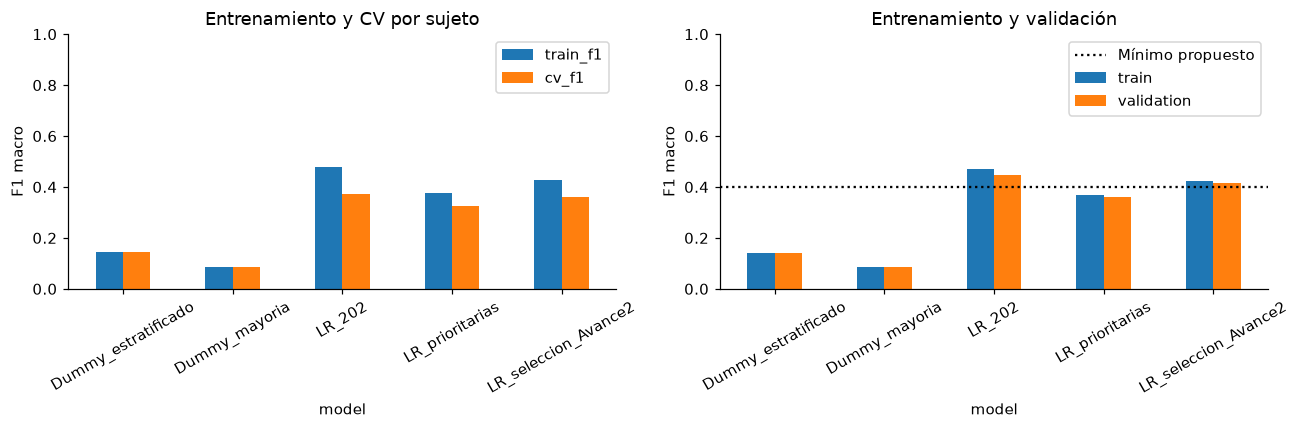

In [7]:
def metrics(y_true, y_pred):
    # Las métricas agregadas se complementan después con errores y soportes por clase.
    return {'f1_macro': float(f1_score(y_true, y_pred, labels=IDS, average='macro', zero_division=0)),
            'balanced_accuracy': float(balanced_accuracy_score(y_true, y_pred)),
            'accuracy': float(accuracy_score(y_true, y_pred))}


fitted, predictions, eval_rows = {}, {}, []
for name, estimator in candidates.items():
    fitted[name] = clone(estimator).fit(X_train, y_train)
    for split, X, y in [('train', X_train, y_train), ('validation', X_val, y_val)]:
        predictions[name, split] = fitted[name].predict(X)
        eval_rows.append({'model': name, 'split': split, **metrics(y, predictions[name, split])})
evaluation = pd.DataFrame(eval_rows)
best_model = fitted[WINNER]
display(evaluation.round(4))
if np.any(best_model.named_steps['classifier'].n_iter_ >= 3000):
    raise RuntimeError('El ganador alcanzó max_iter; revisar convergencia antes de continuar.')
train_metrics = metrics(y_train, predictions[WINNER, 'train'])
val_metrics = metrics(y_val, predictions[WINNER, 'validation'])
gap = train_metrics['f1_macro'] - val_metrics['f1_macro']
print(f'Brecha entrenamiento − validación: {gap:.3f}; alerta (> {GAP_ALERT}): {gap > GAP_ALERT}')
print('Brecha media entrenamiento − CV:', round(float(cv_summary.loc[WINNER, 'gap_f1']), 3))

# Visualizar generalización con los mismos modelos y sin consultar prueba.
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
cv_summary[['train_f1', 'cv_f1']].plot.bar(ax=axes[0], rot=30)
axes[0].set(title='Entrenamiento y CV por sujeto', ylabel='F1 macro', ylim=(0, 1))
evaluation.pivot(index='model', columns='split', values='f1_macro').plot.bar(ax=axes[1], rot=30)
axes[1].axhline(MIN_F1, color='black', linestyle=':', label='Mínimo propuesto')
axes[1].set(title='Entrenamiento y validación', ylabel='F1 macro', ylim=(0, 1))
axes[1].legend()
fig.tight_layout()
plt.show()


## 7. Errores por actividad y por sujeto

La matriz de confusión normalizada por fila muestra el recall de cada actividad; el reporte incluye precisión, recall, F1 y soporte. Se revisan especialmente `PT`, difícil en el histórico, y las confusiones `LF`/`LT` y `PT`/`PF`: la altura de la carga puede requerir información postural que la sEMG no representa suficientemente.

El F1 global agrupa ventanas y pondera indirectamente su cantidad. Por eso también se muestra cada sujeto por separado. Dos sujetos de validación son insuficientes para estimar con precisión la generalización poblacional; la desviación entre folds no equivale a incertidumbre entre todas las personas posibles.


,precision,recall,f1-score,support
N,0.836,0.444,0.580,4283.000
LF,0.234,0.674,0.348,920.000
K,0.730,0.800,0.764,1310.000
PT,0.499,0.145,0.225,1364.000
LT,0.315,0.442,0.368,755.000
W,0.320,0.492,0.388,709.000
PF,0.361,0.606,0.452,649.000
accuracy,0.485,0.485,0.485,0.485
macro avg,0.471,0.515,0.446,9990.000
weighted avg,0.614,0.485,0.496,9990.000


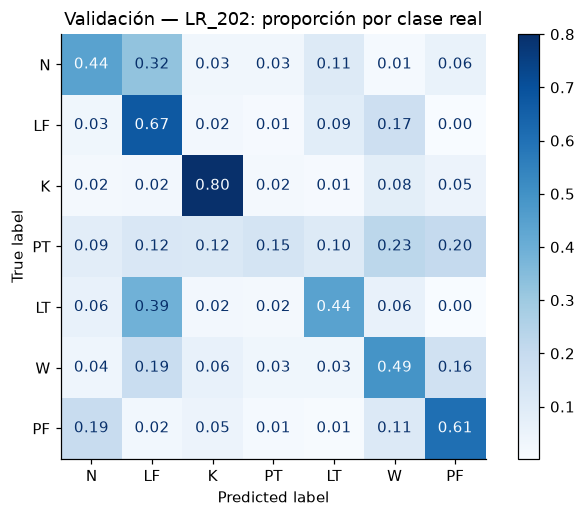

,subject,windows,f1_macro,balanced_accuracy,accuracy
0,11,5954,0.4428,0.5378,0.4934
1,12,4036,0.4311,0.4965,0.4720


In [8]:
# Los reportes usan sólo el ganador congelado; no seleccionan una variante por clase o persona.
val_prediction = predictions[WINNER, 'validation']
val_report = pd.DataFrame(classification_report(
    y_val, val_prediction, labels=IDS, target_names=LABELS, output_dict=True, zero_division=0)).T
display(val_report.round(3))
ConfusionMatrixDisplay.from_predictions(
    y_val, val_prediction, labels=IDS, display_labels=LABELS, normalize='true',
    cmap='Blues', values_format='.2f')
plt.title(f'Validación — {WINNER}: proporción por clase real')
plt.tight_layout()
plt.show()
subject_rows = []
for subject, frame in frames['validation'].groupby('subject'):
    idx = frame.index.to_numpy()
    subject_rows.append({'subject': int(subject), 'windows': len(idx),
                         **metrics(y_val[idx], val_prediction[idx])})
by_subject = pd.DataFrame(subject_rows)
display(by_subject.round(4))


## 8. Características importantes: selección e interpretación visual

La rama `LR_seleccion_Avance2` aplica métodos **filter**: varianza, correlación y asociación por información mutua. Se visualiza además la magnitud media absoluta de los coeficientes del ganador, expresados sobre características escaladas; son asociaciones del modelo lineal, no efectos causales ni unidades de %MVC.

La importancia por permutación mide cuánto disminuye el **F1 macro de validación** al desordenar una variable manteniendo fijo el modelo. Los metadatos no se permutan porque nunca son predictores. Variables descartadas por el pipeline tendrán importancia cero; las correlacionadas pueden sustituirse y parecer poco importantes. Permutar ventanas individualmente también altera su dependencia temporal: el gráfico es exploratorio y las barras de dispersión entre permutaciones no son intervalos de confianza por sujeto.

No se elimina ninguna característica ni se vuelve a seleccionar el modelo con este diagnóstico de validación. Cualquier revisión posterior exige un nuevo protocolo de desarrollo, manteniendo cerrada la prueba.


Ganador: 202 variables finales de 202 originales.


,feature,f1_drop_mean,f1_drop_std
0,ch1_mean,0.1626,0.0035
157,ch8_rms,0.1586,0.0028
166,ch8_relpower_movement,0.1385,0.0015
21,ch2_mean,0.1347,0.0054
145,ch7_relpower_movement,0.1291,0.0025
136,ch7_rms,0.1286,0.0026
19,ch1_relpower_movement,0.1271,0.0026
10,ch1_rms,0.1203,0.0022
165,ch8_relpower_slow,0.1192,0.0028
144,ch7_relpower_slow,0.1172,0.0020


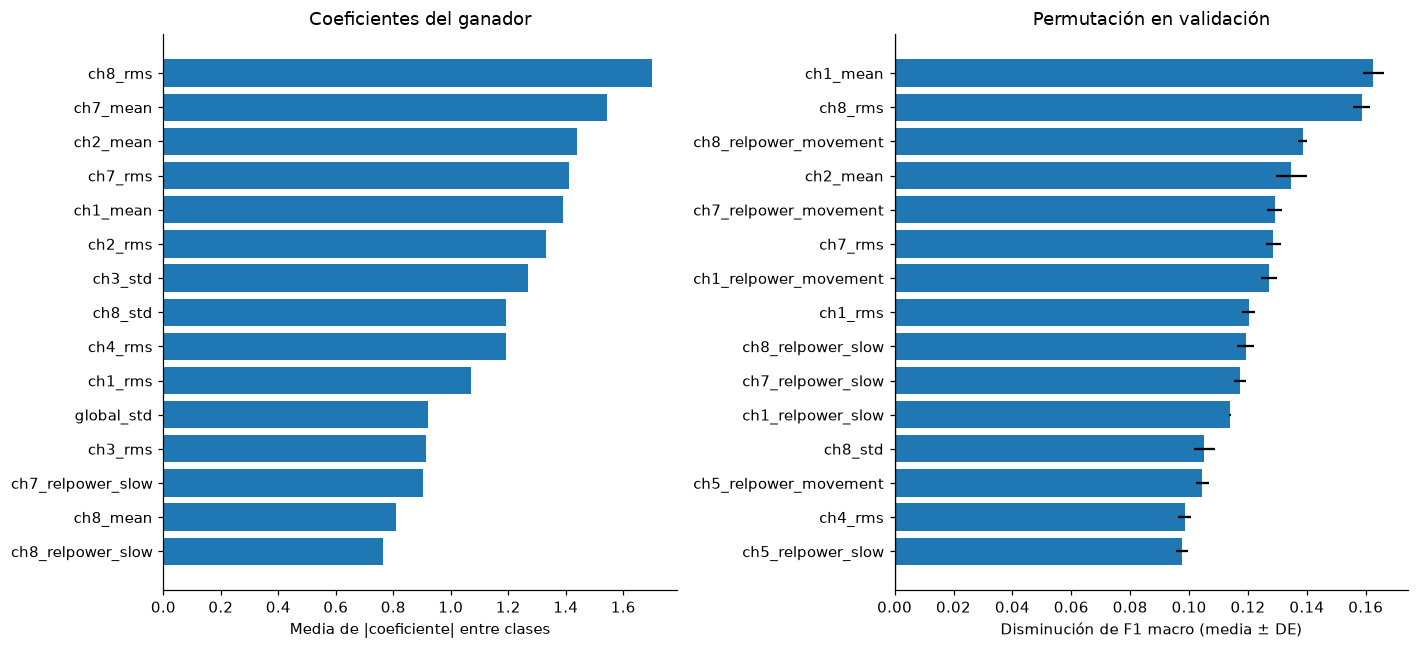

In [9]:
# Recuperar los nombres tras filtros/selección evita asociar coeficientes a columnas equivocadas.
selected_names = best_model[:-1].get_feature_names_out()
coef = np.abs(best_model.named_steps['classifier'].coef_).mean(axis=0)
assert len(selected_names) == len(coef)
coefficient_table = pd.DataFrame({'feature': selected_names, 'mean_abs_coef': coef})
print(f'Ganador: {len(selected_names)} variables finales de {len(FEATURE_COLUMNS)} originales.')

# Evaluar cada variable original atravesando el pipeline completo, sin reajustarlo.
perm = permutation_importance(best_model, X_val, y_val, scoring=f1_scorer,
                              n_repeats=PERM_REPEATS, random_state=SEED, n_jobs=N_JOBS)
importance = pd.DataFrame({'feature': FEATURE_COLUMNS, 'f1_drop_mean': perm.importances_mean,
                           'f1_drop_std': perm.importances_std})
display(importance.sort_values('f1_drop_mean', ascending=False).head(15).round(4))
fig, axes = plt.subplots(1, 2, figsize=(13, 6))
top_coef = coefficient_table.nlargest(15, 'mean_abs_coef').sort_values('mean_abs_coef')
axes[0].barh(top_coef['feature'], top_coef['mean_abs_coef'])
axes[0].set(title='Coeficientes del ganador', xlabel='Media de |coeficiente| entre clases')
top_perm = importance.nlargest(15, 'f1_drop_mean').sort_values('f1_drop_mean')
axes[1].barh(top_perm['feature'], top_perm['f1_drop_mean'], xerr=top_perm['f1_drop_std'])
axes[1].axvline(0, color='black', linewidth=0.8)
axes[1].set(title='Permutación en validación', xlabel='Disminución de F1 macro (media ± DE)')
fig.tight_layout()
plt.show()


## 9. Desempeño mínimo y registro reproducible

La aceptación exploratoria requiere cumplir **simultáneamente** los tres umbrales predefinidos. Se informa también la diferencia respecto al histórico a 12 Hz. Sólo la variante `LR_seleccion_Avance2` reproduce su receta; comparar el ganador con 0.4153 es una referencia contextual y no una demostración estadística de mejora.

Se guardan tablas y un manifiesto con modelo, versiones, variables, umbrales y huellas SHA-256 de las entradas. Las huellas vinculan la evaluación final con los datos y el protocolo concretos. No se guardan cifras ficticias ni salidas de una supuesta ejecución previa.


In [10]:
def acceptance(model_metrics, control_f1):
    # La regla es conjuntiva y se reutiliza sin cambios para validación y prueba.
    checks = {'F1_macro_minimo': model_metrics['f1_macro'] >= MIN_F1,
              'balanced_accuracy_minima': model_metrics['balanced_accuracy'] >= MIN_BAL_ACC,
              'ganancia_sobre_control': model_metrics['f1_macro'] - control_f1 >= MIN_GAIN}
    return {**checks, 'aceptable_exploratorio': all(checks.values())}


dummy_names = [name for name in candidates if name.startswith('Dummy_')]
val_dummy_f1 = max(metrics(y_val, predictions[name, 'validation'])['f1_macro'] for name in dummy_names)
val_acceptance = acceptance(val_metrics, val_dummy_f1)
display(pd.Series(val_acceptance, name='validación').to_frame())
print('Ganancia de F1 sobre el mejor control:', round(val_metrics['f1_macro'] - val_dummy_f1, 4))
if HISTORICAL_F1 is not None:
    print('Diferencia descriptiva frente a 0.4153 histórico:', round(val_metrics['f1_macro'] - HISTORICAL_F1, 4))

# Las lecturas binarias siguientes sólo calculan huellas de los archivos exportados.
input_hashes = {name: hashlib.sha256((EXPORT_DIR / name).read_bytes()).hexdigest() for name in required}
# Una especificación declarativa evita direcciones de memoria presentes en repr(partial(...)).
model_specification = {
    'pipeline_version': 'avance3-v1', 'classifier': 'LogisticRegression',
    'C': 1.0, 'max_iter': 3000, 'solver': 'lbfgs', 'class_weight': 'balanced',
    'columns': PRIORITY_COLUMNS if WINNER == 'LR_prioritarias' else FEATURE_COLUMNS,
    'imputer': 'median', 'variance_threshold': 0.0,
    'scaler': 'RobustScaler' if WINNER == 'LR_seleccion_Avance2' else 'StandardScaler',
    'spearman_threshold': 0.95 if WINNER == 'LR_seleccion_Avance2' else None,
    'mutual_information_percentile': 50 if WINNER == 'LR_seleccion_Avance2' else None,
}
manifest = {'winner': WINNER, 'model_specification': model_specification, 'seed': SEED,
            'target_fs': TARGET_FS, 'feature_columns': FEATURE_COLUMNS,
            'label_order': LABELS, 'sklearn': sklearn.__version__,
            'numpy': np.__version__, 'pandas': pd.__version__, 'n_splits': N_SPLITS,
            'minimums': {'f1': MIN_F1, 'balanced_accuracy': MIN_BAL_ACC, 'gain': MIN_GAIN},
            'inputs_sha256': input_hashes}
fingerprint = hashlib.sha256(json.dumps(manifest, sort_keys=True).encode('utf-8')).hexdigest()
RESULT_DIR.mkdir(parents=True, exist_ok=True)
cv_detail.to_csv(RESULT_DIR / 'cv_folds.csv', index=False)
cv_summary.to_csv(RESULT_DIR / 'cv_resumen.csv')
evaluation.to_csv(RESULT_DIR / 'train_validacion.csv', index=False)
by_subject.to_csv(RESULT_DIR / 'validacion_sujetos.csv', index=False)
val_report.to_csv(RESULT_DIR / 'validacion_clases.csv')
importance.to_csv(RESULT_DIR / 'importancia_permutacion.csv', index=False)
coefficient_table.to_csv(RESULT_DIR / 'coeficientes.csv', index=False)
(RESULT_DIR / 'protocolo.json').write_text(
    json.dumps({**manifest, 'fingerprint': fingerprint, 'validation_metrics': val_metrics,
                'validation_acceptance': val_acceptance}, indent=2, ensure_ascii=False), encoding='utf-8')


,validación
F1_macro_minimo,True
balanced_accuracy_minima,True
ganancia_sobre_control,True
aceptable_exploratorio,True


Ganancia de F1 sobre el mejor control: 0.304
Diferencia descriptiva frente a 0.4153 histórico: 0.0311


10006

## 10. Prueba final con sujetos 13–14: abrir una sola vez

Esta sección completa el criterio de comparación entre entrenamiento y prueba. Hasta abrirla sólo se dispone de evidencia de CV y validación: no se debe declarar desempeño de prueba.

Después de revisar convergencia y congelar el protocolo, cambiar `TEST_OPEN = True` y ejecutar esta celda. Se evalúa el ganador ya entrenado con sujetos 1–10 y los dos controles predefinidos, sin reajustar ni elegir modelos con la prueba. Si existe una evaluación con la misma huella, se muestra el resultado guardado. Si corresponde a otra huella, se detiene para impedir una reevaluación accidental. El archivo local es una salvaguarda operativa, no garantiza por sí solo la independencia del experimento.

La tabla final reúne entrenamiento, validación y prueba. Si prueba no alcanza el mínimo, se documenta el resultado y sus límites; no se modifica el modelo usando estos sujetos como nueva validación.


In [11]:
# El bloque no accede a predicciones de prueba mientras TEST_OPEN siga en False.
if not TEST_OPEN:
    print('Prueba cerrada: falta evaluar el protocolo congelado en sujetos 13–14.')
else:
    test_path = RESULT_DIR / 'prueba_final.json'
    if test_path.exists():
        test_result = json.loads(test_path.read_text(encoding='utf-8'))
        if test_result['fingerprint'] != fingerprint:
            raise RuntimeError('Ya existe una prueba con otro protocolo; no reutilizar test para elegir cambios.')
    else:
        test_frame = feature_table.loc[feature_table['split'].eq('test')].reset_index(drop=True)
        X_test = test_frame[FEATURE_COLUMNS]
        y_test = test_frame['target'].to_numpy(dtype=int)
        assert set(y_test) == set(IDS)
        test_prediction = best_model.predict(X_test)
        test_metrics = metrics(y_test, test_prediction)
        control_metrics = {name: metrics(y_test, fitted[name].predict(X_test)) for name in dummy_names}
        test_dummy_f1 = max(m['f1_macro'] for m in control_metrics.values())
        subject_metrics = []
        for subject, frame in test_frame.groupby('subject'):
            idx = frame.index.to_numpy()
            subject_metrics.append({'subject': int(subject), 'windows': len(idx),
                                    **metrics(y_test[idx], test_prediction[idx])})
        test_result = {'fingerprint': fingerprint, 'winner': WINNER, 'metrics': test_metrics,
                       'controls': control_metrics, 'subjects': subject_metrics,
                       'acceptance': acceptance(test_metrics, test_dummy_f1),
                       'classification_report': classification_report(
                           y_test, test_prediction, labels=IDS, target_names=LABELS,
                           output_dict=True, zero_division=0)}
        # El modo exclusivo evita sobrescribir una evaluación existente.
        with test_path.open('x', encoding='utf-8') as handle:
            json.dump(test_result, handle, indent=2, ensure_ascii=False)
    final_comparison = pd.DataFrame({'train': train_metrics, 'validation': val_metrics,
                                    'test': test_result['metrics']}).T
    display(final_comparison.round(4))
    display(pd.DataFrame(test_result['subjects']).round(4))
    display(pd.DataFrame(test_result['classification_report']).T.round(3))
    display(pd.Series(test_result['acceptance'], name='prueba').to_frame())
    print('Brecha entrenamiento − prueba:', round(
        train_metrics['f1_macro'] - test_result['metrics']['f1_macro'], 4))


Prueba cerrada: falta evaluar el protocolo congelado en sujetos 13–14.


## 11. Conclusiones

Los resultados guardados corresponden a **12 Hz**, ventanas de **4 segundos**, **43,233 ventanas de entrenamiento** y **9,990 de validación**. La regresión logística con las 202 características constituye un baseline útil y cumple los mínimos exploratorios en validación. La evidencia todavía no permite cerrar la evaluación final: **la prueba con sujetos 13–14 permanece cerrada**.

### 11.1 Algoritmo seleccionado y utilidad del baseline

**`LR_202` fue seleccionado exclusivamente mediante validación cruzada por sujeto**, con F1 macro medio de **0.3720 ± 0.0281**. La desviación es entre los cinco folds; no representa un intervalo de confianza. La comparación de variantes fue:

| Variante | F1 macro en CV, media ± DE | F1 macro en validación |
|---|---:|---:|
| `LR_202` | **0.3720 ± 0.0281** | **0.4464** |
| `LR_seleccion_Avance2` | 0.3609 ± 0.0422 | 0.4160 |
| `LR_prioritarias` | 0.3246 ± 0.0253 | 0.3591 |

El ganador supera en validación al control estratificado (**0.1423**) y al mayoritario (**0.0857**) en F1 macro. Esto aporta evidencia de información predictiva en las características sEMG dentro de esta cohorte y protocolo. La ventaja de CV frente a la selección del Avance 2 es de sólo **0.0111**; estos resultados descriptivos no demuestran una diferencia estadísticamente significativa.

La reducción a 32 variables prioritarias disminuye el desempeño en esta ejecución. Se conserva por tanto el baseline con **202 variables finales**, sin concluir que todas sean indispensables ni que la selección de características carezca de utilidad. La comparación sugiere que conviene evaluar combinaciones más amplias de características antes de adoptar una reducción agresiva.

### 11.2 Características relevantes e interpretación

Los coeficientes de mayor magnitud media absoluta corresponden a `ch8_rms` (**1.7011**), `ch7_mean` (**1.5427**), `ch2_mean` (**1.4402**), `ch7_rms` (**1.4105**) y `ch1_mean` (**1.3896**). Destacan medidas del nivel de activación; también aparecen variables de dispersión como `ch3_std` y `ch8_std`.

La importancia por permutación complementa esta lectura. Las mayores disminuciones medias de F1 macro de validación aparecen al permutar `ch1_mean` (**0.1626**), `ch8_rms` (**0.1586**), `ch8_relpower_movement` (**0.1385**), `ch2_mean` (**0.1347**) y `ch7_relpower_movement` (**0.1291**). También destacan las potencias relativas de la banda lenta de los canales 1, 7 y 8. El modelo utiliza tanto nivel de activación como distribución espectral de la envolvente; no sólo las variables de dinámica y cola priorizadas previamente.

Estas medidas describen asociaciones del modelo, no efectos fisiológicos causales. Los coeficientes dependen del escalamiento y de la redundancia. **Las caídas por permutación no deben sumarse ni interpretarse como aportaciones independientes**: desordenar una variable rompe relaciones entre estadísticas y canales correlacionados, además de la dependencia entre ventanas. La dispersión entre permutaciones tampoco mide incertidumbre por sujeto.

### 11.3 Subajuste, sobreajuste y generalización entre sujetos

| Conjunto | F1 macro | Exactitud balanceada | Exactitud global |
|---|---:|---:|---:|
| Entrenamiento completo, sujetos 1–10 | 0.4688 | 0.5182 | 0.5200 |
| CV por sujeto, media de folds retenidos | 0.3720 | 0.4098 | 0.4398 |
| Validación, sujetos 11–12 | 0.4464 | 0.5147 | 0.4848 |
| Prueba, sujetos 13–14 | Pendiente | Pendiente | Pendiente |

En validación, la brecha de F1 macro respecto al entrenamiento completo es **0.0225**, inferior a la alerta de 0.10. Sin embargo, en CV el F1 medio de entrenamiento de los folds es **0.4795**, frente a **0.3720** en sus sujetos retenidos: una brecha de **0.1075**, que sí activa la alerta. Ambas comparaciones usan ajustes y personas diferentes; la pequeña brecha de validación no descarta la dificultad de generalizar observada en CV.

Hay indicios de sobreajuste o cambio de distribución entre sujetos, sin evidencia suficiente para atribuir la brecha exclusivamente a uno de estos mecanismos. El desempeño moderado incluso en entrenamiento también es compatible con una frontera lineal limitada o con solapamiento entre actividades en la señal; no permite demostrar por sí solo subajuste ni un límite irreducible del problema.

Los sujetos 11 y 12 obtienen F1 macro de **0.4428** y **0.4311**, respectivamente. La proximidad entre ambos es favorable para esta partición, pero dos sujetos no bastan para establecer estabilidad poblacional. **La comparación entrenamiento–prueba sigue pendiente** y no debe sustituirse por la de entrenamiento–validación.

### 11.4 Métrica adecuada y errores por actividad

F1 macro continúa siendo la métrica principal porque el desempeño es desigual entre actividades. El control mayoritario alcanza **0.4287 de exactitud global**, pero sólo **0.0857 de F1 macro** y **0.1429 de exactitud balanceada**. Para `LR_202`, la exactitud global sube a **0.4848**, mientras que F1 macro y exactitud balanceada llegan a **0.4464** y **0.5147**: la comparación muestra por qué la exactitud global aislada oculta errores relevantes.

| Actividad | Precisión | Recall | F1 |
|---|---:|---:|---:|
| `N` | 0.836 | 0.444 | 0.580 |
| `LF` | 0.234 | 0.674 | 0.348 |
| `K` | 0.730 | 0.800 | 0.764 |
| `PT` | 0.499 | 0.145 | 0.225 |
| `LT` | 0.315 | 0.442 | 0.368 |
| `W` | 0.320 | 0.492 | 0.388 |
| `PF` | 0.361 | 0.606 | 0.452 |

`K` es la actividad mejor reconocida. **`PT` sigue siendo la principal debilidad**, con recall de **0.145**: se pierde la mayoría de sus ventanas reales. `LF` presenta recall alto y precisión baja, lo que indica numerosos falsos positivos; `LT` y `PF` también requieren revisar sus confusiones. La elevada precisión y el menor recall de `N` muestran que tampoco basta con medir aciertos en las clases activas. Cumplir un umbral agregado no garantiza reconocimiento adecuado de todas las actividades.

### 11.5 Desempeño mínimo y continuidad con el histórico

El ganador cumple simultáneamente los tres criterios predefinidos **en validación**:

| Criterio | Mínimo propuesto | Resultado | Cumplimiento |
|---|---:|---:|---|
| F1 macro | 0.40 | 0.4464 | Sí |
| Exactitud balanceada | 0.45 | 0.5147 | Sí |
| Ganancia de F1 frente al mejor control trivial | 0.10 | 0.3040 | Sí |

La diferencia descriptiva respecto al F1 macro histórico de **0.4153** es **+0.0311**. La variante que reproduce la receta del Avance 2 obtiene **0.4160**, próxima a ese antecedente; el ganador utiliza una receta distinta y su ventaja no debe presentarse como una mejora estadísticamente demostrada.

El baseline es **aceptable para la evaluación exploratoria de viabilidad**, con limitaciones claras por actividad y por sujeto. Los mínimos no son criterios de despliegue ni incorporan todavía los costos de falsos positivos y falsos negativos del negocio.

### 11.6 Alcance de las conclusiones y siguiente etapa

Se mantiene `LR_202` como referencia congelada para comparar CPC–GRU y CPC–xLSTM en `06_CPC_fs_configurable.ipynb`, conservando frecuencia, ventanas, particiones y métricas. Las comparaciones de desarrollo deberán revisar tanto F1 macro como recall de `PT`, precisión de `LF` y variación entre sujetos. Las importancias observadas no autorizan por sí solas a eliminar variables ni a seleccionar otro modelo con validación.

La evaluación sigue siendo offline: el filtrado de fase cero del Avance 2 impide afirmar causalidad de extremo a extremo o desempeño en tiempo real. La cohorte pequeña, el protocolo controlado y la dependencia entre ventanas limitan la extrapolación a otras personas y movimientos libres. **La prueba con sujetos 13–14 debe permanecer reservada hasta congelar todas las decisiones que se llevarán a evaluación final**; aún no puede afirmarse que el baseline alcance el desempeño mínimo en prueba.

**Fuentes locales utilizadas:** `criterios_semana_3.txt`; `Avance1.Equipo1.ipynb` (calidad, desbalance y protocolo); `avance2.equipo1.ipynb` (secciones 1, 3, 6 y 8); `06_CPC_fs_configurable.ipynb` (secciones 1, 2, 5, 9, 11 y 12). No se ejecuta ni se importa ninguno de estos notebooks.
